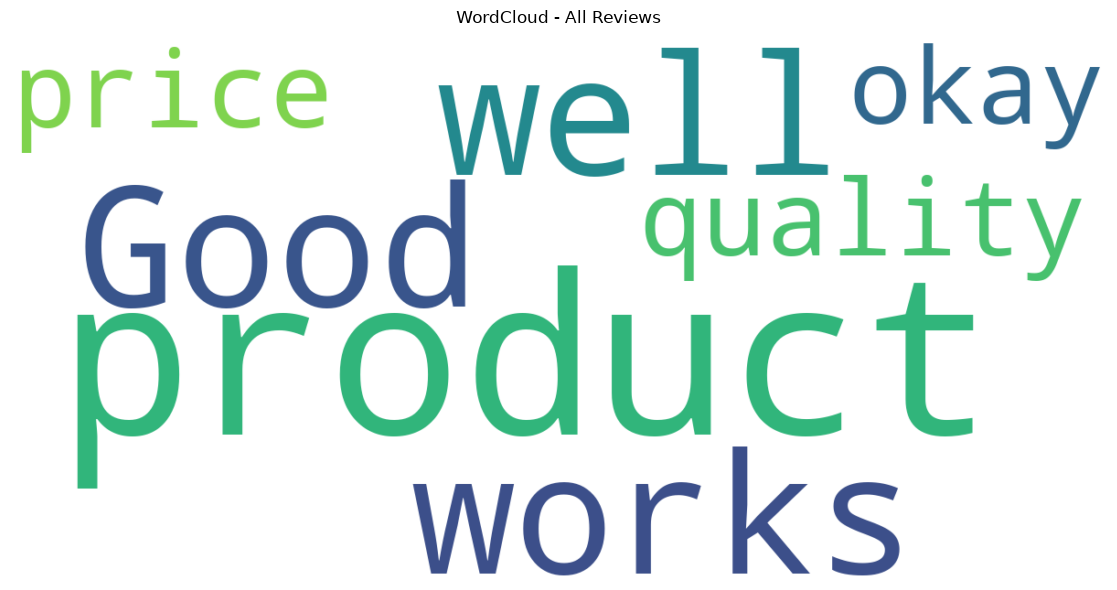

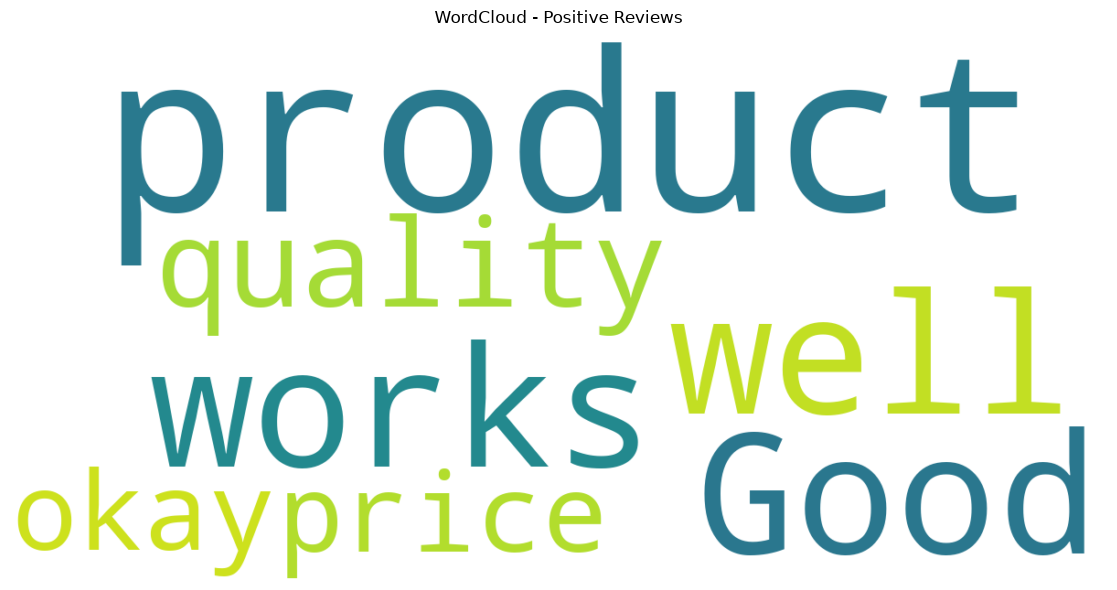

No text available for: WordCloud - Negative Reviews
sentiment
Positive    3
Name: count, dtype: int64
WordCloud images saved successfully.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
# Load extracted reviews
df = pd.read_csv("product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)
# Initialize sentiment analyzer
analyzer = SentimentIntensityAnalyzer()
def classify_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"
df["sentiment"] = df["review"].apply(classify_sentiment)
def generate_wordcloud(text, title, filename):
    if not text.strip():
        print(f"No text available for: {title}")
        return

    cloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        max_words=150,
        collocations=False
    ).generate(text)
    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
# All reviews
all_text = " ".join(df["review"])
generate_wordcloud(
    all_text, "WordCloud - All Reviews", "wordcloud_all.png"
)
# Positive reviews
positive_text = " ".join(
    df.loc[df["sentiment"] == "Positive", "review"]
)
generate_wordcloud(
    positive_text, "WordCloud - Positive Reviews",
    "wordcloud_positive.png"
)
# Negative reviews
negative_text = " ".join(
    df.loc[df["sentiment"] == "Negative", "review"]
)
generate_wordcloud(
    negative_text, "WordCloud - Negative Reviews",
    "wordcloud_negative.png"
)
df.to_csv("product_reviews_analyzed.csv", index=False)
print(df["sentiment"].value_counts())
print("WordCloud images saved successfully.")


In [1]:
%pip install pandas matplotlib wordcloud vaderSentiment

Defaulting to user installation because normal site-packages is not writeable
  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 472.0 kB/s eta 0:00:20
   -- ------------------------------------- 0.5/9.5 MB 472.0 kB/s eta 0:00:20
   -- ------------------------------------- 0.5/9.5 MB 472.0 kB/s eta 0:00:20
   -- ------------------------------------- 0.5/9.5 MB 472.0 kB/s eta 0:00:20
   -- ------------------------------------- 0.5/9.5 MB 472.0 kB/s eta 0:00:20
   --- ------------------------------------ 0.8/9.5 MB 328.9 kB/s eta 0:00:27
   --- -----------------------------

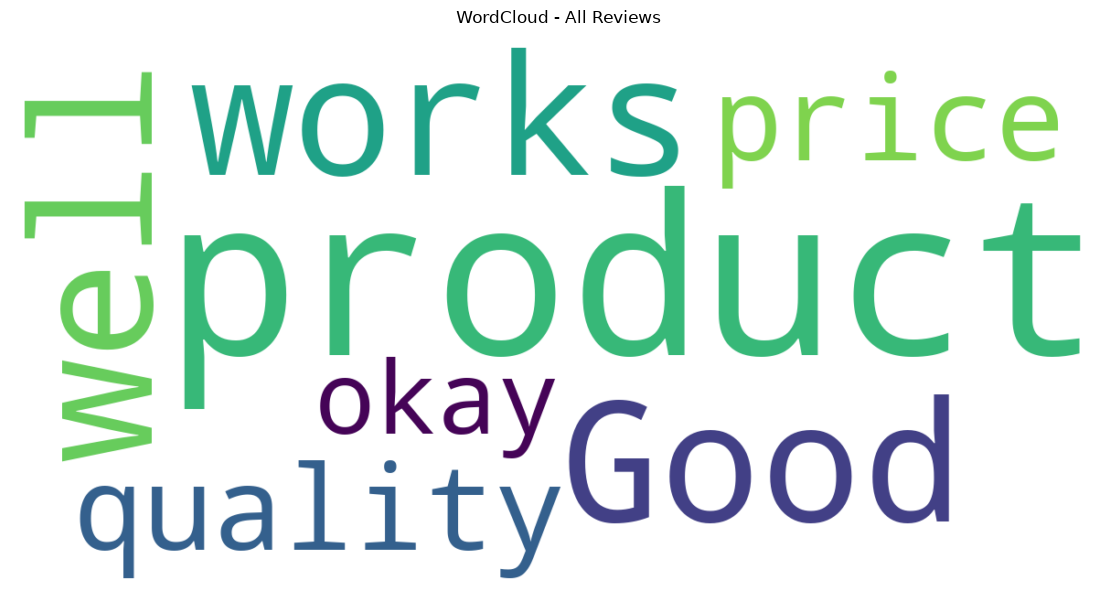

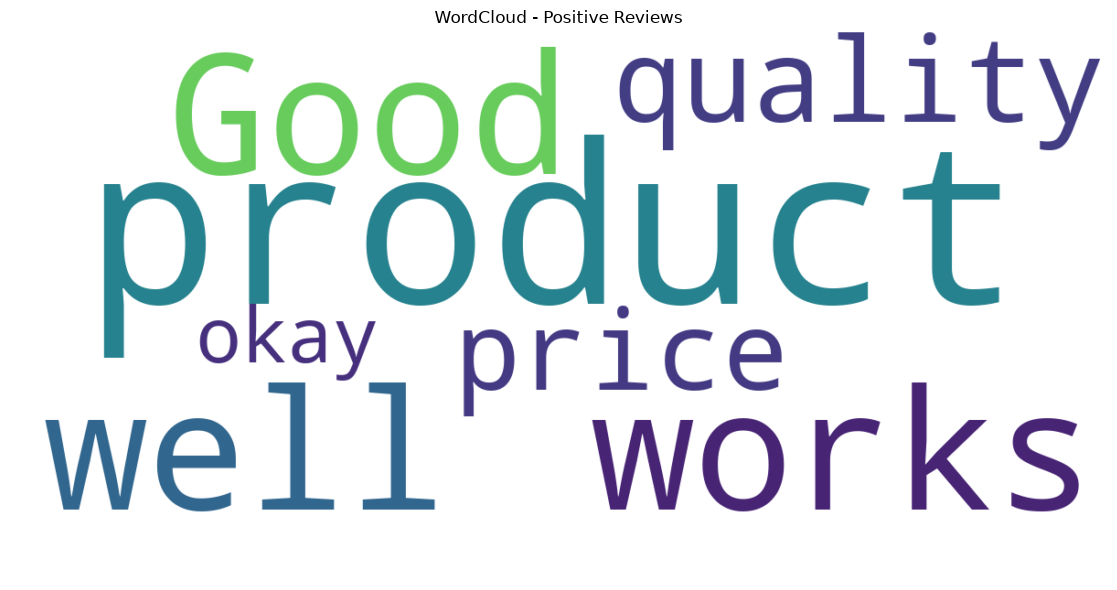

No text available for: WordCloud - Negative Reviews

Sentiment counts:
sentiment
Positive    3
Name: count, dtype: int64

Analyzed reviews saved successfully.
Check the current folder for the CSV and word cloud images.


In [2]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Check whether the CSV file exists
if not os.path.exists("product_reviews.csv"):
    raise FileNotFoundError(
        "product_reviews.csv not found. "
        "Save the CSV in the notebook's current folder."
    )

# Load extracted reviews
df = pd.read_csv("product_reviews.csv")

if "review" not in df.columns:
    raise ValueError("The CSV file must contain a 'review' column.")

df["review"] = df["review"].fillna("").astype(str)

# Initialize sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

def classify_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

# Classify each review
df["sentiment"] = df["review"].apply(classify_sentiment)

def generate_wordcloud(text, title, filename):
    if not text.strip():
        print(f"No text available for: {title}")
        return

    cloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        max_words=150,
        collocations=False
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# Word cloud for all reviews
all_text = " ".join(df["review"])
generate_wordcloud(
    all_text,
    "WordCloud - All Reviews",
    "wordcloud_all.png"
)

# Word cloud for positive reviews
positive_text = " ".join(
    df.loc[df["sentiment"] == "Positive", "review"]
)
generate_wordcloud(
    positive_text,
    "WordCloud - Positive Reviews",
    "wordcloud_positive.png"
)

# Word cloud for negative reviews
negative_text = " ".join(
    df.loc[df["sentiment"] == "Negative", "review"]
)
generate_wordcloud(
    negative_text,
    "WordCloud - Negative Reviews",
    "wordcloud_negative.png"
)

# Save analyzed data
df.to_csv("product_reviews_analyzed.csv", index=False)

print("\nSentiment counts:")
print(df["sentiment"].value_counts())
print("\nAnalyzed reviews saved successfully.")
print("Check the current folder for the CSV and word cloud images.")
